<h1>Mini-Batch Gradient Descent</h1>

In [81]:
import numpy as np
import matplotlib.pyplot as plt

In [82]:
m = 200

rng = np.random.default_rng(seed=42)

x = 2*rng.random((m, 1))
y = 4 + 3*x + rng.standard_normal((m, 1))

In [83]:
from sklearn.preprocessing import add_dummy_feature

In [84]:
x_b = add_dummy_feature(x)

In [85]:
eta = 0.1
n_epochs = 1000
batch_size = 20

In [86]:
theta = rng.standard_normal ((2,1))
theta

array([[0.76013309],
       [0.22921137]])

In [87]:
#comenzamos con valores aleatorios y nos acercamos con cada ciclo a la solucion
for epoch in range (n_epochs):
    #mesclar los indices de los datos usando rng.permutation
    shuffled_indices = rng.permutation(m)

    x_b_shuffled = x_b[shuffled_indices]
    y_shuffled = y[shuffled_indices]

    #creamos los mini-batchs
    for start in range(0, m, batch_size):

        end = start + batch_size

        x_batch = x_b_shuffled[start:end]
        y_batch = y_shuffled[start:end]

        #calculamos error y gradiente para cada grupo
        y_predict = x_batch @ theta
        error = y_predict - y_batch

        gradients = (2 / len(x_batch)) * x_batch.T @ error

        #actualizamos theta para el siguiente ciclo
        theta = theta - eta * gradients
theta

array([[3.62247157],
       [3.28050581]])

In [88]:
x_pred = np.array([[0], [2]])
x_pred_b = add_dummy_feature(x_pred)

y_pred = x_pred_b @ theta

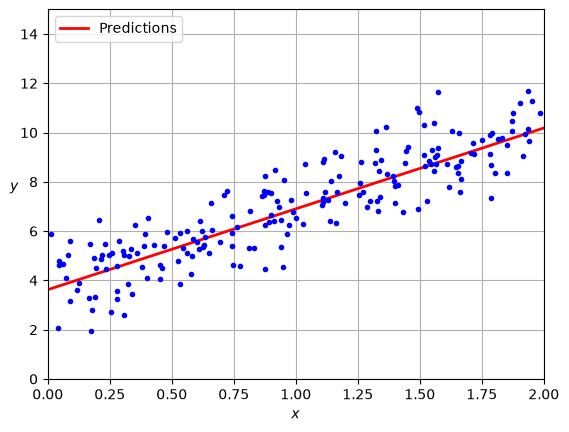

In [94]:
plt.plot (x_pred, y_pred, 'r-', linewidth=2, label= 'Predictions')
plt.plot (x, y, 'b.')

plt.xlabel('$x$')
plt.ylabel('$y$', rotation=0)
plt.legend(loc = 'upper left')
plt.axis([0, 2, 0, 15])
plt.grid(True)
plt.show()